# Candidate gene — full comparison (infection contexts, pairwise, butyrate dose)

Same figure as the IL-8 one, for any gene: set `GENE` in the first code cell.
Sources identical to `17_IL8_full_comparison` (feat_df for A06, lfc-difference for pairwise,
A04 DE tables for butyrate). Output saved as `<GENE>_full_comparison.png`.


In [5]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt
A06 = Path(os.environ.get('A06_PROJ', str(Path.home()/'Projects_shared/epithelial_coinfection-model_WORKING')))
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
FIG = A04/'results/figures'; FIG.mkdir(parents=True, exist_ok=True)
# ============================================================
# >>> CHANGE THIS ONE LINE to focus on a different gene <<<
GENE = 'IRAK2'
# Candidates we discussed (drop any symbol above):
#   Chaperone/UPR arm : HSPA5 CALR WFS1 CRYAB BAG3 CLU
#   UPR sensors       : XBP1 ATF4 ATF6 EIF2AK3 GSK3B
#   Central TF/hubs   : HSF1 RELA NFKB1 REL RELB JUN IRF1 STAT3 MYC CEBPB CEBPD
#   NF-kB relay       : IRAK2 TRAF6 IKBKE TAB2 TNFAIP3 NFKBIZ BIRC3
#   Sensors (entry)   : DDX58 IFIH1 ZBP1 RIPK2 TLR2
#   Chemokine outputs : CXCL8 CXCL1 CXCL2 CXCL3 CCL20
#   Metabolic (Bt arm): SP1 PCK1 CYP11A1 SLC22A4
# ============================================================
mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'axes.linewidth':0.8,'axes.edgecolor':'#444','axes.spines.top':False,'axes.spines.right':False,
  'xtick.color':'#444','ytick.color':'#444','figure.dpi':140,'savefig.dpi':300,'savefig.bbox':'tight'})

# ---- feat_df (exact correlation-figure source) ----
feat_path=None
for p in ['analysis/causal_v6/full_feature_matrix.csv','analysis/causal_v4/full_feature_matrix.csv','analysis/causal_v2/full_feature_matrix.csv']:
    if (A06/p).exists(): feat_path=A06/p; break
feat_df=pd.read_csv(feat_path, index_col='gene')
print('feat_df:',feat_path,'|',feat_df.shape)
def gl(cond):  # lfc for a vs-Mock condition
    return float(feat_df.loc[GENE, f'lfc_{cond}']) if GENE in feat_df.index else np.nan
def gp(cond):
    return float(feat_df.loc[GENE, f'padj_{cond}']) if GENE in feat_df.index else np.nan

feat_df: /home/job37yv/Projects_shared/epithelial_coinfection-model_WORKING/analysis/causal_v6/full_feature_matrix.csv | (766, 43)


In [6]:
rows=[]
# 1) infection context (vs Mock) — straight from feat_df
for cond,label in [('Cd','Cd vs Mock'),('Co','Co-infection vs Mock'),('Bt','Bt vs Mock')]:
    rows.append(dict(label=label,group='infection context',lfc=gl(cond),padj=gp(cond)))

# 2) PAIRWISE correlation-figure contrasts = difference of vs-Mock LFC (what the scatter plots)
#    Bt vs Cd  => lfc_Bt - lfc_Cd ; Cd vs Co => lfc_Cd - lfc_Co ; Bt vs Co => lfc_Bt - lfc_Co
for a,b,label in [('Bt','Cd','Bt vs Cd'),('Cd','Co','Cd vs Co'),('Bt','Co','Bt vs Co')]:
    rows.append(dict(label=label,group='correlation pairwise',lfc=gl(a)-gl(b),
                     padj=min(gp(a),gp(b))))   # padj: most-significant of the two (indicative)

# 3) A04 butyrate doses
def de_val(fname):
    f=A04/'results/tables'/fname
    if not f.exists(): print('MISSING',fname); return (np.nan,np.nan)
    d=pd.read_csv(f,index_col=0)
    for col in ['gene_name','symbol','Gene','gene']:
        if col in d.columns: d=d.set_index(col); break
    d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    if GENE not in d.index: return (np.nan,np.nan)
    r=d.loc[GENE]; return float(r.get('log2FoldChange',np.nan)),float(r.get('padj',np.nan))
for fn,label,grp in [('DE_Butyrate_5v0_Mock.csv','But 5mM (Mock)','butyrate only'),
                     ('DE_Butyrate_10v0_Mock.csv','But 10mM (Mock)','butyrate only'),
                     ('DE_Butyrate_5v0_Cd.csv','But 5mM (Cd)','butyrate + infection'),
                     ('DE_Butyrate_10v0_Cd.csv','But 10mM (Cd)','butyrate + infection')]:
    l,p=de_val(fn); rows.append(dict(label=label,group=grp,lfc=l,padj=p))

df=pd.DataFrame(rows)
print(df.round(3).to_string())

                  label                 group    lfc   padj
0            Cd vs Mock     infection context  1.247  0.007
1  Co-infection vs Mock     infection context  0.449  0.387
2            Bt vs Mock     infection context  0.372  0.790
3              Bt vs Cd  correlation pairwise -0.875  0.007
4              Cd vs Co  correlation pairwise  0.797  0.007
5              Bt vs Co  correlation pairwise -0.077  0.387
6        But 5mM (Mock)         butyrate only -0.955  0.051
7       But 10mM (Mock)         butyrate only -1.641  0.000
8          But 5mM (Cd)  butyrate + infection -0.486  0.248
9         But 10mM (Cd)  butyrate + infection -0.889  0.006


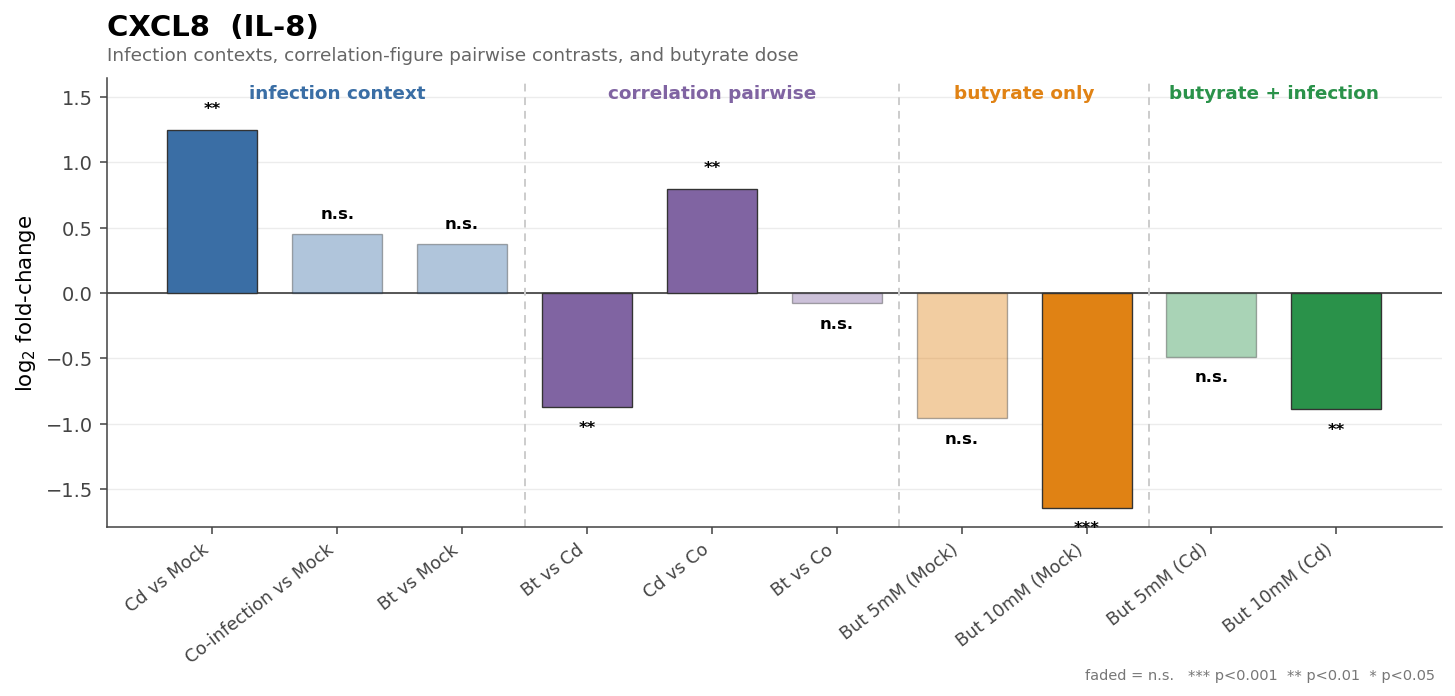

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/figures/IRAK2_full_comparison.png


In [7]:
def stars(p):
    if pd.isna(p): return 'n.s.'
    return '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'n.s.'
order=['infection context','correlation pairwise','butyrate only','butyrate + infection']
gcol={'infection context':'#3a6ea5','correlation pairwise':'#8064a2','butyrate only':'#e08214','butyrate + infection':'#2a924a'}
df=df.dropna(subset=['lfc']).copy()
df['go']=df.group.map({g:i for i,g in enumerate(order)}); df=df.sort_values('go').reset_index(drop=True)
n=len(df); x=np.arange(n)
alphas=[1.0 if (not pd.isna(p) and p<0.05) else 0.4 for p in df.padj]
fig,ax=plt.subplots(figsize=(max(9,0.85*n+2),5.4))
bars=ax.bar(x,df.lfc,color=[gcol[g] for g in df.group],edgecolor='#333',lw=.7,width=.72,zorder=3)
for b,a in zip(bars,alphas): b.set_alpha(a)
for xi,(_,r) in zip(x,df.iterrows()):
    ax.text(xi,r.lfc+(0.1 if r.lfc>=0 else -0.1),stars(r.padj),ha='center',
            va='bottom' if r.lfc>=0 else 'top',fontsize=8.5,fontweight='bold')
ax.axhline(0,color='#444',lw=.9)
ylo,yhi=ax.get_ylim(); ax.set_ylim(ylo,yhi*1.18)
for g in order:
    sub=df[df.group==g]
    if len(sub)==0: continue
    lo,hi=sub.index.min(),sub.index.max()
    if hi<n-1: ax.axvline(hi+0.5,color='#ccc',ls=(0,(4,3)),lw=1)
    ax.text((lo+hi)/2,ax.get_ylim()[1]*0.97,g,ha='center',va='top',fontsize=9.5,color=gcol[g],fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(df.label,rotation=38,ha='right',fontsize=9)
ax.set_ylabel('log$_2$ fold-change',fontsize=11)
ax.set_title('CXCL8  (IL-8)',fontsize=15,fontweight='bold',loc='left',pad=22)
ax.text(0,1.04,'Infection contexts, correlation-figure pairwise contrasts, and butyrate dose',transform=ax.transAxes,fontsize=9.5,color='#666')
ax.grid(axis='y',color='#ececec',lw=.7,zorder=0)
ax.text(0.995,-0.34,'faded = n.s.   *** p<0.001  ** p<0.01  * p<0.05',transform=ax.transAxes,ha='right',fontsize=7.5,color='#777')
plt.tight_layout(); fig.savefig(FIG/f'{GENE}_full_comparison.png'); plt.show()
print('wrote',FIG/f'{GENE}_full_comparison.png')

## Optional: render a whole candidate list in one run


In [8]:
# ---- OPTIONAL: render a whole list of candidates in one run ----
# Reruns the same extraction+plot for each gene, saving <GENE>_full_comparison.png each.
CANDIDATES = ['CXCL8','CXCL1','CXCL2','CXCL3','CCL20',
              'HSPA5','CALR','WFS1','CRYAB','BAG3','CLU',
              'XBP1','ATF4','ATF6','EIF2AK3','GSK3B',
              'HSF1','RELA','NFKB1','REL','RELB','JUN','IRF1','STAT3','MYC','CEBPB','CEBPD',
              'IRAK2','TRAF6','IKBKE','TAB2','TNFAIP3','NFKBIZ','BIRC3',
              'DDX58','IFIH1','ZBP1','RIPK2','TLR2',
              'SP1','PCK1','CYP11A1','SLC22A4']

import matplotlib.pyplot as plt
def build_df(gene):
    rows=[]
    for cond,label in [('Cd','Cd vs Mock'),('Co','Co-infection vs Mock'),('Bt','Bt vs Mock')]:
        rows.append(dict(label=label,group='infection context',
                         lfc=(float(feat_df.loc[gene,f'lfc_{cond}']) if gene in feat_df.index else np.nan),
                         padj=(float(feat_df.loc[gene,f'padj_{cond}']) if gene in feat_df.index else np.nan)))
    def gl(c): return float(feat_df.loc[gene,f'lfc_{c}']) if gene in feat_df.index else np.nan
    def gp(c): return float(feat_df.loc[gene,f'padj_{c}']) if gene in feat_df.index else np.nan
    for a,b,label in [('Bt','Cd','Bt vs Cd'),('Cd','Co','Cd vs Co'),('Bt','Co','Bt vs Co')]:
        rows.append(dict(label=label,group='correlation pairwise',lfc=gl(a)-gl(b),
                         padj=min([x for x in [gp(a),gp(b)] if not np.isnan(x)],default=np.nan)))
    def de_val(fname):
        f=A04/'results/tables'/fname
        if not f.exists(): return (np.nan,np.nan)
        d=pd.read_csv(f,index_col=0)
        for col in ['gene_name','symbol','Gene','gene']:
            if col in d.columns: d=d.set_index(col); break
        d.index=[re.sub(r'\\..*','',str(i)) for i in d.index]
        if gene not in d.index: return (np.nan,np.nan)
        r=d.loc[gene]; return float(r.get('log2FoldChange',np.nan)),float(r.get('padj',np.nan))
    for fn,label,grp in [('DE_Butyrate_5v0_Mock.csv','But 5mM (Mock)','butyrate only'),
                         ('DE_Butyrate_10v0_Mock.csv','But 10mM (Mock)','butyrate only'),
                         ('DE_Butyrate_5v0_Cd.csv','But 5mM (Cd)','butyrate + infection'),
                         ('DE_Butyrate_10v0_Cd.csv','But 10mM (Cd)','butyrate + infection')]:
        l,p=de_val(fn); rows.append(dict(label=label,group=grp,lfc=l,padj=p))
    return pd.DataFrame(rows)

def stars(p):
    if pd.isna(p): return 'n.s.'
    return '***' if p<1e-3 else '**' if p<1e-2 else '*' if p<0.05 else 'n.s.'
order=['infection context','correlation pairwise','butyrate only','butyrate + infection']
gcol={'infection context':'#3a6ea5','correlation pairwise':'#8064a2','butyrate only':'#e08214','butyrate + infection':'#2a924a'}

def plot_gene(gene):
    d=build_df(gene).dropna(subset=['lfc']).copy()
    if d.empty:
        print(f'  {gene}: no data (not found) — skipped'); return
    d['go']=d.group.map({g:i for i,g in enumerate(order)}); d=d.sort_values('go').reset_index(drop=True)
    n=len(d); x=np.arange(n); alphas=[1.0 if (not pd.isna(p) and p<0.05) else 0.4 for p in d.padj]
    fig,ax=plt.subplots(figsize=(max(9,0.85*n+2),5.4))
    bars=ax.bar(x,d.lfc,color=[gcol[g] for g in d.group],edgecolor='#333',lw=.7,width=.72,zorder=3)
    for b,a in zip(bars,alphas): b.set_alpha(a)
    for xi,(_,r) in zip(x,d.iterrows()):
        ax.text(xi,r.lfc+(0.1 if r.lfc>=0 else -0.1),stars(r.padj),ha='center',
                va='bottom' if r.lfc>=0 else 'top',fontsize=8.5,fontweight='bold')
    ax.axhline(0,color='#444',lw=.9); ylo,yhi=ax.get_ylim(); ax.set_ylim(ylo,yhi*1.18)
    for g in order:
        sub=d[d.group==g]
        if len(sub)==0: continue
        lo,hi=sub.index.min(),sub.index.max()
        if hi<n-1: ax.axvline(hi+0.5,color='#ccc',ls=(0,(4,3)),lw=1)
        ax.text((lo+hi)/2,ax.get_ylim()[1]*0.97,g,ha='center',va='top',fontsize=9.5,color=gcol[g],fontweight='bold')
    ax.set_xticks(x); ax.set_xticklabels(d.label,rotation=38,ha='right',fontsize=9)
    ax.set_ylabel('log$_2$ fold-change',fontsize=11)
    ax.set_title(gene,fontsize=15,fontweight='bold',loc='left',pad=22)
    ax.text(0,1.04,'Infection contexts, correlation-figure pairwise contrasts, and butyrate dose',transform=ax.transAxes,fontsize=9.5,color='#666')
    ax.grid(axis='y',color='#ececec',lw=.7,zorder=0)
    ax.text(0.995,-0.34,'faded = n.s.   *** p<0.001  ** p<0.01  * p<0.05',transform=ax.transAxes,ha='right',fontsize=7.5,color='#777')
    plt.tight_layout(); fig.savefig(FIG/f'{gene}_full_comparison.png'); plt.close(fig)
    print(f'  wrote {gene}_full_comparison.png')

for g in CANDIDATES: plot_gene(g)
print('done ->', FIG)

  wrote CXCL8_full_comparison.png
  wrote CXCL1_full_comparison.png
  wrote CXCL2_full_comparison.png
  wrote CXCL3_full_comparison.png
  wrote CCL20_full_comparison.png
  wrote HSPA5_full_comparison.png
  wrote CALR_full_comparison.png
  wrote WFS1_full_comparison.png
  wrote CRYAB_full_comparison.png
  wrote BAG3_full_comparison.png
  wrote CLU_full_comparison.png
  wrote XBP1_full_comparison.png
  wrote ATF4_full_comparison.png
  wrote ATF6_full_comparison.png
  wrote EIF2AK3_full_comparison.png
  wrote GSK3B_full_comparison.png
  wrote HSF1_full_comparison.png
  wrote RELA_full_comparison.png
  wrote NFKB1_full_comparison.png
  wrote REL_full_comparison.png
  wrote RELB_full_comparison.png
  wrote JUN_full_comparison.png
  wrote IRF1_full_comparison.png
  wrote STAT3_full_comparison.png
  wrote MYC_full_comparison.png
  wrote CEBPB_full_comparison.png
  wrote CEBPD_full_comparison.png
  wrote IRAK2_full_comparison.png
  wrote TRAF6_full_comparison.png
  wrote IKBKE_full_comparison.